# Capítulo 2. Ecuaciones de primer orden
## Sección 2.8.1. Aplicaciones completas: Burgers y modelo LWR

**Fuentes principales:**

- página 5 de `Ecuacione Lineales De Primer Orden.pdf`;
- temario oficial, apartado 2.8;
- Exámenes Generales 2023-1, 2025-2 y 2026-1.

Esta sección reúne las herramientas construidas anteriormente:

$$
\text{características}
\longrightarrow
\text{soluciones débiles}
\longrightarrow
\text{Rankine--Hugoniot}
\longrightarrow
\text{entropía}
\longrightarrow
\text{problema de Riemann}
\longrightarrow
\text{interacción de ondas}.
$$

### Objetivos

Al terminar se deberá poder:

1. interpretar físicamente la ecuación de Burgers;
2. deducir el modelo de tráfico Lighthill--Whitham--Richards;
3. distinguir velocidad de vehículos y velocidad de ondas;
4. decidir choque o rarefacción a partir de la convexidad del flujo;
5. resolver datos por tramos antes de la primera interacción;
6. calcular el primer tiempo de interacción;
7. continuar la solución después de una interacción choque--rarefacción;
8. verificar conservación de masa y condiciones de entropía;
9. resolver familias paramétricas que contienen los patrones de los exámenes históricos.

La escena Manim queda lista para ejecutarse localmente en resolución $2560\times1440$ y $120$ fps. No se ejecuta ni se compila durante la generación.

### Ejemplo gráfico complementario · Diagrama fundamental de tráfico

En el tráfico el cociente $q(\rho)/\rho$ es la rapidez media de los autos y la derivada $q'(\rho)$ es la rapidez de una pequeña perturbación. Entre $\rho=0.2$ y $0.9$, el flujo baja de $0.16$ a $0.09$. La pendiente de la secante es $-0.1$. La cola avanza hacia atrás mientras los autos de ambos lados siguen moviéndose hacia adelante.


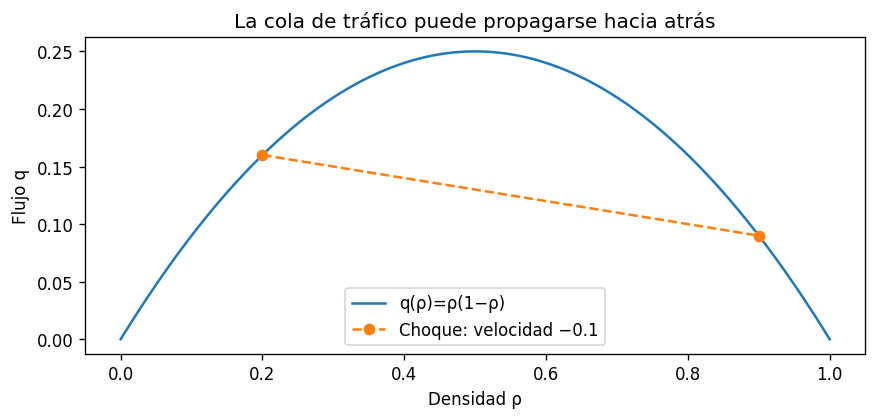

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.4,3.6))
d=np.linspace(0,1,300)
ax.plot(d,d*(1-d),label="q(ρ)=ρ(1−ρ)")
estados=np.array([0.2,0.9])
ax.plot(estados, estados*(1-estados),"o--",label="Choque: velocidad −0.1")
ax.set(xlabel="Densidad ρ",ylabel="Flujo q",title="La cola de tráfico puede propagarse hacia atrás")
ax.legend()
fig.tight_layout()
plt.show()

[Abrir la animación original · 33.2 s](media/videos/LINEALES/1440p120/BurgersLWRInteraccion.mp4)

# Fuentes del temario y de los exámenes

## Notas manuscritas: Burgers no viscoso

> **Fuente visual no incluida en el repositorio:** Página 5 de las notas. Referencia original: `assets/notas_pagina_05.png`.

## Temario oficial: aplicaciones

> **Fuente visual no incluida en el repositorio:** Página 2 del temario oficial. Referencia original: `assets/temario_oficial_pagina_02.png`.

## Examen 2023-1

> **Fuente visual no incluida en el repositorio:** Examen 2023-1. Referencia original: `assets/examen_2023_1_pagina_01.png`.

## Examen 2025-2

> **Fuente visual no incluida en el repositorio:** Examen 2025-2. Referencia original: `assets/examen_2025_2_pagina_01.png`.

## Examen 2026-1

> **Fuente visual no incluida en el repositorio:** Examen 2026-1. Referencia original: `assets/examen_2026_1_pagina_01.png`.

> **Criterio editorial.** Los ejercicios históricos se usan para identificar el nivel, la geometría y los tipos de interacción exigidos. Los desarrollos trabajados se presentan en familias paramétricas, de manera que los datos históricos aparezcan como casos particulares y no como soluciones aisladas memorizadas.

# 2.8.1. Transcripción y síntesis de las notas

En la página 5 se introduce la ecuación de Burgers no viscosa:

$$
\begin{cases}
u_t+u u_x=0,
&
x\in\mathbb{R},
\quad
t>0,
\\
u(x,0)=f(x),
&
x\in\mathbb{R}.
\end{cases}
$$

Se reconoce como ley de conservación con flujo

$$
F(u)=\frac{u^2}{2},
$$

pues

$$
u_t+\partial_x\left(\frac{u^2}{2}\right)=0.
$$

El sistema característico es

$$
\frac{dx}{ds}=u,
$$

$$
\frac{dt}{ds}=1,
$$

$$
\frac{du}{ds}=0.
$$

Con datos en

$$
t=0,
$$

la parametrización característica es

$$
x(s,\xi)=\xi+s f(\xi),
$$

$$
t(s,\xi)=s,
$$

$$
u(s,\xi)=f(\xi).
$$

Por tanto, mientras el mapa

$$
\xi\longmapsto \xi+t f(\xi)
$$

sea invertible, la solución clásica satisface

$$
u(x,t)=f(\xi),
$$

con

$$
x=\xi+t f(\xi).
$$

> **Complemento.** Después de la pérdida de invertibilidad se requiere la teoría de soluciones débiles y entrópicas desarrollada en las secciones 2.5--2.7.

# 2.8.2. Dos modelos y dos geometrías del flujo

## Definición 2.8.1 — Ecuación de Burgers no viscosa

La ecuación de Burgers es

$$
u_t+\left(\frac{u^2}{2}\right)_x=0.
$$

Su flujo es

$$
f_B(u)=\frac{u^2}{2}.
$$

Se tiene

$$
f_B'(u)=u,
$$

y

$$
f_B''(u)=1>0.
$$

Por tanto, el flujo es estrictamente convexo.

## Interpretación 2.8.2 — Velocidad transportada

La forma no conservativa es

$$
u_t+u u_x=0.
$$

El propio valor $u$ es la velocidad característica. Regiones con mayor valor de $u$ se desplazan más rápidamente.

Si detrás hay valores grandes y delante valores pequeños, las características se comprimen y aparece un choque.

Si detrás hay valores pequeños y delante valores grandes, las características se separan y aparece una rarefacción.

## Definición 2.8.3 — Modelo LWR adimensional

Sea

$$
0\leq\rho(x,t)\leq1
$$

la densidad vehicular adimensional.

Se adopta la relación velocidad--densidad

$$
v(\rho)=1-\rho.
$$

El flujo vehicular es

$$
f_T(\rho)
=
\rho v(\rho)
=
\rho(1-\rho).
$$

La conservación de vehículos conduce a

$$
\boxed{
\rho_t+\bigl(\rho(1-\rho)\bigr)_x=0
}.
$$

## Observación 2.8.4 — Concavidad del flujo de tráfico

Se tiene

$$
f_T'(\rho)=1-2\rho,
$$

y

$$
f_T''(\rho)=-2<0.
$$

El flujo es estrictamente cóncavo.

## Aclaración 2.8.5 — Velocidad de vehículos y velocidad de ondas

La velocidad de un vehículo es

$$
v(\rho)=1-\rho.
$$

La velocidad característica de una perturbación de densidad es

$$
a(\rho)=f_T'(\rho)=1-2\rho.
$$

Estas cantidades no son iguales.

Para

$$
\rho>\frac12,
$$

se tiene

$$
a(\rho)<0,
$$

aunque

$$
v(\rho)>0.
$$

Los vehículos avanzan, pero una perturbación de congestión puede propagarse hacia atrás.

## Tabla comparativa

| Modelo | Flujo | Curvatura | Salto creciente | Salto decreciente |
|---|---|---:|---|---|
| Burgers | $f_B(u)=u^2/2$ | $f_B''=1>0$ | rarefacción | choque |
| LWR | $f_T(\rho)=\rho(1-\rho)$ | $f_T''=-2<0$ | choque | rarefacción |

# 2.8.3. Método para datos por tramos

## Procedimiento 2.8.6 — Seguimiento de frentes

Sea el dato inicial constante por tramos.

### Paso 1. Localizar los saltos

Cada discontinuidad inicial genera un problema de Riemann local.

### Paso 2. Clasificar cada onda

Para cada salto se determina:

- choque mediante Rankine--Hugoniot;
- rarefacción mediante la inversa de $f'$;
- orientación entrópica usando convexidad o concavidad.

### Paso 3. Escribir la solución antes de la interacción

Las ondas evolucionan de manera independiente mientras sus regiones no se intersecten.

### Paso 4. Calcular el primer tiempo de interacción

Se igualan las trayectorias de las fronteras relevantes.

### Paso 5. Continuar después de la interacción

Si un choque entra en una rarefacción, el estado a un lado del choque deja de ser constante. La condición de Rankine--Hugoniot se convierte en una ecuación diferencial para la trayectoria del frente.

### Paso 6. Verificar

Se comprueban:

$$
\text{Rankine--Hugoniot},
$$

$$
\text{entropía},
$$

$$
\text{conservación de masa},
$$

y continuidad con la solución previa en el tiempo de interacción.

# 2.8.4. Bloque compacto para Burgers

## Problema 2.8.7 — Familia paramétrica

Sean

$$
A>0
$$

y

$$
L>0.
$$

Considérese

$$
u_t+u u_x=0
$$

con dato

$$
u_0(x)
=
\begin{cases}
0, & x<0,\\
A, & 0\leq x\leq L,\\
0, & x>L.
\end{cases}
$$

El caso

$$
A=L=1
$$

contiene la geometría del problema del Examen General 2025-2.

## Análisis de los saltos iniciales

### Salto en $x=0$

Los estados son

$$
u_L=0,
$$

$$
u_R=A.
$$

Como el flujo de Burgers es convexo y el salto es creciente, se genera una rarefacción:

$$
u(x,t)
=
\frac{x}{t}
$$

en

$$
0<x<At.
$$

### Salto en $x=L$

Los estados son

$$
u_L=A,
$$

$$
u_R=0.
$$

Se genera un choque con velocidad

$$
\sigma
=
\frac{A+0}{2}
=
\frac{A}{2}.
$$

Su trayectoria inicial es

$$
x=L+\frac{A}{2}t.
$$

## Proposición 2.8.8 — Solución antes de la interacción

Mientras

$$
At<L+\frac{A}{2}t,
$$

la solución entrópica es

$$
u(x,t)
=
\begin{cases}
0,
&
x<0,
\\
\dfrac{x}{t},
&
0\leq x<At,
\\
A,
&
At\leq x<L+\dfrac{A}{2}t,
\\
0,
&
x\geq L+\dfrac{A}{2}t.
\end{cases}
$$

## Proposición 2.8.9 — Primer tiempo de interacción

La frontera derecha de la rarefacción satisface

$$
x=At.
$$

El choque satisface

$$
x=L+\frac{A}{2}t.
$$

La primera interacción ocurre cuando

$$
At
=
L+\frac{A}{2}t.
$$

Por tanto,

$$
\boxed{
t_B^*
=
\frac{2L}{A}
},
$$

y

$$
\boxed{
x_B^*
=
2L
}.
$$

# 2.8.5. Burgers después de la interacción

**Complemento · Cómo continuar cuando el abanico alcanza al choque.** Antes del encuentro el frente de Burgers mira a su izquierda un estado constante $A$. Después, en su posición $X(t)$ encuentra el valor del abanico $X(t)/t$. Rankine–Hugoniot con estado derecho cero se convierte en $X'=X/(2t)$. Hay una segunda manera de reconocer la ley: el perfil triangular encierra la masa $X^2/(2t)=AL$. La masa inicial fija la constante de integración y ambas deducciones dan $X=\sqrt{2ALt}$ en esa etapa.


## Proposición 2.8.10 — Ecuación del choque dentro de la rarefacción

Después de

$$
t=t_B^*,
$$

el choque separa:

- a la izquierda, el estado de la rarefacción
  $$
  u_L(t)=\frac{s_B(t)}{t};
  $$
- a la derecha, el estado
  $$
  u_R=0.
  $$

Rankine--Hugoniot da

$$
s_B'(t)
=
\frac{u_L(t)+u_R}{2}
=
\frac{s_B(t)}{2t}.
$$

La condición de empalme es

$$
s_B\left(\frac{2L}{A}\right)=2L.
$$

## Teorema 2.8.11 — Trayectoria posterior

La ecuación

$$
s_B'=\frac{s_B}{2t}
$$

tiene solución

$$
s_B(t)=C\sqrt{t}.
$$

Usando la condición de empalme,

$$
\boxed{
s_B(t)=\sqrt{2ALt}
}
$$

para

$$
t\geq\frac{2L}{A}.
$$

## Teorema 2.8.12 — Solución entrópica para todo tiempo

Para

$$
0<t<\frac{2L}{A},
$$

se usa la solución de cuatro regiones anterior.

Para

$$
t\geq\frac{2L}{A},
$$

la solución es

$$
\boxed{
u(x,t)
=
\begin{cases}
0,
&
x<0,
\\
\dfrac{x}{t},
&
0\leq x<\sqrt{2ALt},
\\
0,
&
x>\sqrt{2ALt}.
\end{cases}
}
$$

En el choque,

$$
u_L(t)
=
\sqrt{\frac{2AL}{t}},
$$

y

$$
u_R=0.
$$

## Verificación 2.8.13 — Conservación de masa

La masa inicial es

$$
\int_{\mathbb{R}}u_0(x)\,dx
=
AL.
$$

Después de la interacción,

$$
\int_{\mathbb{R}}u(x,t)\,dx
=
\int_0^{\sqrt{2ALt}}\frac{x}{t}\,dx.
$$

Por tanto,

$$
\int_{\mathbb{R}}u(x,t)\,dx
=
\frac{1}{2t}
\left(2ALt\right)
=
AL.
$$

La masa se conserva exactamente.


# 2.8.6. Compresión suave y formación de choque

## Problema 2.8.14 — Rampa afín

Sean

$$
A>0,
$$

$$
L>0,
$$

y

$$
u_0(x)
=
\begin{cases}
A, & x<0,\\
A\left(1-\dfrac{x}{L}\right), & 0\leq x\leq L,\\
0, & x>L.
\end{cases}
$$

El caso

$$
A=L=1
$$

contiene la geometría del problema de Burgers del Examen General 2023-1.

## Proposición 2.8.15 — Solución clásica antes de la ruptura

En la zona afín,

$$
u_0(\xi)
=
A\left(1-\frac{\xi}{L}\right).
$$

Las características satisfacen

$$
x
=
\xi+tA\left(1-\frac{\xi}{L}\right)
=
At+
\left(
1-\frac{At}{L}
\right)\xi.
$$

Mientras

$$
1-\frac{At}{L}>0,
$$

el mapa es invertible.

Se obtiene

$$
u(x,t)
=
\begin{cases}
A,
&
x<At,
\\
\dfrac{A(L-x)}{L-At},
&
At\leq x\leq L,
\\
0,
&
x>L.
\end{cases}
$$

## Corolario 2.8.16 — Tiempo de ruptura

El jacobiano es

$$
\frac{\partial x}{\partial\xi}
=
1-\frac{At}{L}.
$$

Por tanto, la ruptura ocurre en

$$
\boxed{
t_c=\frac{L}{A}
}.
$$

Todas las características de la rampa se concentran en

$$
(x_c,t_c)
=
\left(
L,\frac{L}{A}
\right).
$$

## Resultado añadido 2.8.17 — Continuación entrópica

Después de la ruptura se forma un choque entre los estados $A$ y $0$.

La velocidad es

$$
\sigma=\frac{A}{2}.
$$

La trayectoria que parte de $(x_c,t_c)$ es

$$
\boxed{
s(t)
=
L+\frac{A}{2}
\left(
t-\frac{L}{A}
\right)
=
\frac{At+L}{2}
}.
$$

Para

$$
t\geq\frac{L}{A},
$$

la solución entrópica es

$$
u(x,t)
=
\begin{cases}
A, & x<s(t),\\
0, & x>s(t).
\end{cases}
$$

# 2.8.7. Deducción e interpretación del modelo LWR

## Definición 2.8.18 — Densidad y flujo

Sea

$$
\rho(x,t)
$$

la densidad de vehículos.

Si los vehículos se mueven con velocidad media

$$
v(\rho),
$$

el flujo de vehículos es

$$
q(\rho)=\rho v(\rho).
$$

La conservación sobre un intervalo $[a,b]$ exige

$$
\frac{d}{dt}
\int_a^b\rho(x,t)\,dx
=
q(\rho(a,t))-q(\rho(b,t)).
$$

Localizando,

$$
\rho_t+q(\rho)_x=0.
$$

## Modelo lineal velocidad--densidad

En variables adimensionales se toma

$$
v(\rho)=1-\rho.
$$

Por tanto,

$$
q(\rho)=\rho(1-\rho).
$$

## Observación 2.8.19 — Capacidad de la vía

El flujo es máximo cuando

$$
q'(\rho)=1-2\rho=0.
$$

Así,

$$
\rho_c=\frac12,
$$

y

$$
q_{\max}=\frac14.
$$

Densidades mayores que $\rho_c$ representan el régimen congestionado.

## Interpretación 2.8.20 — Choque de tráfico

Un choque representa una transición brusca entre dos densidades.

Su velocidad es

$$
\sigma
=
\frac{
\rho_R(1-\rho_R)
-
\rho_L(1-\rho_L)
}{
\rho_R-\rho_L
}.
$$

Simplificando,

$$
\boxed{
\sigma
=
1-\rho_L-\rho_R
}.
$$

Un valor negativo significa que la frontera de congestión se mueve hacia atrás respecto de la carretera.

# 2.8.8. Bloque compacto para LWR

## Problema 2.8.21 — Familia paramétrica

Sean

$$
0<\rho_m\leq1
$$

y

$$
L>0.
$$

Considérese

$$
\rho_t+\bigl(\rho(1-\rho)\bigr)_x=0
$$

con

$$
\rho_0(x)
=
\begin{cases}
0, & x<0,\\
\rho_m, & 0\leq x\leq L,\\
0, & x>L.
\end{cases}
$$

El caso

$$
\rho_m=L=1
$$

contiene la geometría del problema del Examen General 2026-1.

## Salto izquierdo: $0\longrightarrow\rho_m$

El flujo es cóncavo. Un salto creciente es un choque entrópico.

La velocidad es

$$
\sigma_L
=
\frac{f(\rho_m)-f(0)}{\rho_m-0}
=
1-\rho_m.
$$

La trayectoria es

$$
x=(1-\rho_m)t.
$$

## Salto derecho: $\rho_m\longrightarrow0$

Un salto decreciente genera una rarefacción.

Las velocidades extremas son

$$
a(\rho_m)=1-2\rho_m,
$$

y

$$
a(0)=1.
$$

Como

$$
a^{-1}(\xi)=\frac{1-\xi}{2},
$$

la rarefacción centrada en $x=L$ es

$$
\rho(x,t)
=
\frac{1}{2}
\left(
1-\frac{x-L}{t}
\right).
$$

## Proposición 2.8.22 — Solución antes de la interacción

Mientras

$$
(1-\rho_m)t
<
L+(1-2\rho_m)t,
$$

se tiene

$$
\rho(x,t)
=
\begin{cases}
0,
&
x<(1-\rho_m)t,
\\
\rho_m,
&
(1-\rho_m)t
\leq x
<
L+(1-2\rho_m)t,
\\
\dfrac12
\left(
1-\dfrac{x-L}{t}
\right),
&
L+(1-2\rho_m)t
\leq x
<
L+t,
\\
0,
&
x\geq L+t.
\end{cases}
$$

## Proposición 2.8.23 — Primer tiempo de interacción

La interacción ocurre cuando

$$
(1-\rho_m)t
=
L+(1-2\rho_m)t.
$$

Por tanto,

$$
\boxed{
t_T^*
=
\frac{L}{\rho_m}
},
$$

y

$$
\boxed{
x_T^*
=
\frac{(1-\rho_m)L}{\rho_m}
}.
$$

# 2.8.9. LWR después de la interacción

## Proposición 2.8.24 — Ecuación del choque dentro de la rarefacción

Después de la interacción, el choque separa:

- a la izquierda,
  $$
  \rho_L=0;
  $$
- a la derecha, el estado de la rarefacción
  $$
  \rho_R(t)
  =
  \frac12
  \left(
  1-\frac{s_T(t)-L}{t}
  \right).
  $$

Rankine--Hugoniot da

$$
s_T'(t)
=
\frac{f(\rho_R)-f(0)}{\rho_R-0}
=
1-\rho_R.
$$

Sustituyendo el valor de $\rho_R$,

$$
s_T'(t)
=
\frac12
+
\frac{s_T(t)-L}{2t}.
$$

La condición de empalme es

$$
s_T\left(\frac{L}{\rho_m}\right)
=
\frac{(1-\rho_m)L}{\rho_m}.
$$

## Teorema 2.8.25 — Trayectoria posterior

La ecuación anterior tiene solución

$$
\boxed{
s_T(t)
=
L+t-2\sqrt{L\rho_m t}
}
$$

para

$$
t\geq\frac{L}{\rho_m}.
$$

Equivalentemente,

$$
s_T(t)
=
\left(
\sqrt{t}-\sqrt{L\rho_m}
\right)^2
+
L(1-\rho_m).
$$

En el caso

$$
\rho_m=1,
$$

se reduce a

$$
s_T(t)
=
\left(
\sqrt{t}-\sqrt{L}
\right)^2.
$$

## Corolario 2.8.26 — Densidad a la derecha del choque

Se obtiene

$$
\boxed{
\rho_R(t)
=
\sqrt{\frac{L\rho_m}{t}}
}.
$$

La densidad del embotellamiento junto al frente decrece como

$$
t^{-1/2}.
$$

## Teorema 2.8.27 — Solución para todo tiempo después de la interacción

Para

$$
t\geq\frac{L}{\rho_m},
$$

la solución es

$$
\boxed{
\rho(x,t)
=
\begin{cases}
0,
&
x<s_T(t),
\\
\dfrac12
\left(
1-\dfrac{x-L}{t}
\right),
&
s_T(t)<x<L+t,
\\
0,
&
x>L+t.
\end{cases}
}
$$

## Verificación 2.8.28 — Conservación del número de vehículos

La masa inicial es

$$
\int_{\mathbb{R}}\rho_0(x)\,dx
=
L\rho_m.
$$

Después de la interacción,

$$
\int_{\mathbb{R}}\rho(x,t)\,dx
=
\int_{s_T(t)}^{L+t}
\frac12
\left(
1-\frac{x-L}{t}
\right)
\,dx.
$$

Usando la fórmula de $s_T(t)$, el resultado es

$$
\int_{\mathbb{R}}\rho(x,t)\,dx
=
L\rho_m.
$$

El número total de vehículos se conserva.

# 2.8.10. Comparación estructural de las interacciones

## Burgers

El bloque genera

$$
\text{rarefacción}
+
\text{choque}.
$$

La rarefacción alcanza al choque en

$$
t_B^*=\frac{2L}{A}.
$$

Después,

$$
s_B(t)=\sqrt{2ALt}.
$$

## LWR

El bloque genera

$$
\text{choque}
+
\text{rarefacción}.
$$

La rarefacción alcanza al choque en

$$
t_T^*=\frac{L}{\rho_m}.
$$

Después,

$$
s_T(t)=L+t-2\sqrt{L\rho_m t}.
$$

## Principio común

En ambos casos, después de la interacción, uno de los estados del choque pertenece a una rarefacción y depende de

$$
\frac{s(t)}{t}
$$

o de

$$
\frac{s(t)-L}{t}.
$$

Rankine--Hugoniot deja de producir una velocidad constante y se transforma en una EDO para la trayectoria del frente.

## Técnica de examen

En un problema con datos por tramos conviene presentar la solución en este orden:

1. convexidad o concavidad de $f$;
2. problemas de Riemann iniciales;
3. velocidades de fronteras;
4. solución antes de la interacción;
5. tiempo y punto de interacción;
6. trazas variables después de la interacción;
7. EDO de Rankine--Hugoniot;
8. verificación de entropía;
9. conservación de masa;
10. unicidad por contracción $L^1$.

# 2.8.11. Visualización Manim: interacción de ondas

La escena compara los datos de bloque con

$$
A=1,
$$

$$
\rho_m=1,
$$

$$
L=1.
$$

## Burgers

El tiempo de interacción es

$$
t_B^*=2.
$$

Después,

$$
s_B(t)=\sqrt{2t}.
$$

## LWR

El tiempo de interacción es

$$
t_T^*=1.
$$

Después,

$$
s_T(t)=\left(\sqrt{t}-1\right)^2.
$$

La animación muestra simultáneamente:

- los perfiles $u(x,t)$ y $\rho(x,t)$;
- los diagramas espacio--tiempo;
- las rarefacciones;
- los choques;
- los puntos de interacción;
- la rebanada temporal.

Los perfiles iniciales, los ejes y las fórmulas permanecen visibles durante cuatro segundos antes de iniciar la evolución. El tiempo se actualiza con `DecimalNumber`. No se reconstruye ningún `MathTex` dentro de los cuadros.

In [ ]:
import os
import shutil
import tempfile
import uuid
from pathlib import Path

def miktex_candidates():
    candidates = []
    for base in (
        os.environ.get("LOCALAPPDATA"),
        os.environ.get("ProgramFiles"),
        os.environ.get("ProgramFiles(x86)"),
    ):
        if not base:
            continue
        root = Path(base)
        candidates.extend([
            root / "Programs" / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "Programs" / "MiKTeX" / "miktex" / "bin",
            root / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "MiKTeX" / "miktex" / "bin",
        ])
    return candidates

for candidate in miktex_candidates():
    if candidate.exists():
        os.environ["PATH"] = (
            str(candidate)
            + os.pathsep
            + os.environ.get("PATH", "")
        )

latex_exe = shutil.which("latex")
dvisvgm_exe = shutil.which("dvisvgm")

if latex_exe is None or dvisvgm_exe is None:
    raise RuntimeError(
        "No se encontraron latex.exe y dvisvgm.exe. "
        "Abre MiKTeX Console, completa la instalación y reinicia el kernel."
    )

from manim import config, __version__ as manim_version

TEX_RUNTIME_DIR = (
    Path(tempfile.gettempdir())
    / f"manim_tex_burgers_lwr_{os.getpid()}_{uuid.uuid4().hex[:10]}"
)
TEX_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"

print(f"Manim Community: {manim_version}")
print("latex   :", latex_exe)
print("dvisvgm :", dvisvgm_exe)
print("TeX dir :", TEX_RUNTIME_DIR)
print("Render preparado: 2560×1440, 120 fps")
print("La animación no ha sido compilada.")

In [ ]:
%%manim -v WARNING -r 2560,1440 --fps 120 BurgersLWRInteraccion

from manim import *
import numpy as np

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"

T_FINAL = 4.0
LENGTH = 1.0


class BurgersLWRInteraccion(Scene):
    def construct(self):
        self.camera.background_color = "#0B1020"

        color_burgers = ORANGE
        color_lwr = TEAL_C
        color_fan = BLUE_B
        color_shock = YELLOW_C
        color_time = GREEN_C
        color_zero = GREY_B

        title = Text(
            "Burgers y LWR: interacción de rarefacciones y choques",
            font_size=38,
            weight=BOLD,
            color=WHITE,
        ).to_edge(UP, buff=0.16)

        equation = MathTex(
            r"u_t+\left(\frac{u^2}{2}\right)_x=0",
            r"\qquad\qquad",
            r"\rho_t+\bigl(\rho(1-\rho)\bigr)_x=0",
            font_size=31,
        ).next_to(title, DOWN, buff=0.10)

        equation[0].set_color(color_burgers)
        equation[2].set_color(color_lwr)

        self.play(
            FadeIn(title, shift=0.10 * DOWN),
            Write(equation),
            run_time=1.8,
        )

        time = ValueTracker(0.0)

        # --------------------------------------------------------
        # Ejes de perfiles
        # --------------------------------------------------------

        burgers_profile_axes = Axes(
            x_range=[-1.0, 5.0, 1.0],
            y_range=[0.0, 1.25, 0.25],
            x_length=5.85,
            y_length=2.35,
            tips=False,
            axis_config={
                "stroke_width": 2,
                "include_numbers": True,
                "font_size": 17,
            },
        ).move_to(3.55 * LEFT + 1.02 * UP)

        lwr_profile_axes = Axes(
            x_range=[-1.0, 5.0, 1.0],
            y_range=[0.0, 1.25, 0.25],
            x_length=5.85,
            y_length=2.35,
            tips=False,
            axis_config={
                "stroke_width": 2,
                "include_numbers": True,
                "font_size": 17,
            },
        ).move_to(3.55 * RIGHT + 1.02 * UP)

        burgers_profile_labels = burgers_profile_axes.get_axis_labels(
            MathTex(r"x", font_size=25),
            MathTex(r"u", font_size=25),
        )

        lwr_profile_labels = lwr_profile_axes.get_axis_labels(
            MathTex(r"x", font_size=25),
            MathTex(r"\rho", font_size=25),
        )

        burgers_heading = Text(
            "Burgers: bloque 0–1–0",
            font_size=26,
            weight=SEMIBOLD,
            color=color_burgers,
        ).next_to(burgers_profile_axes, UP, buff=0.08)

        lwr_heading = Text(
            "LWR: bloque 0–1–0",
            font_size=26,
            weight=SEMIBOLD,
            color=color_lwr,
        ).next_to(lwr_profile_axes, UP, buff=0.08)

        # --------------------------------------------------------
        # Ejes espacio-tiempo
        # --------------------------------------------------------

        burgers_xt_axes = Axes(
            x_range=[-1.0, 5.0, 1.0],
            y_range=[0.0, T_FINAL, 1.0],
            x_length=5.85,
            y_length=2.35,
            tips=False,
            axis_config={
                "stroke_width": 2,
                "include_numbers": True,
                "font_size": 17,
            },
        ).move_to(3.55 * LEFT + 2.15 * DOWN)

        lwr_xt_axes = Axes(
            x_range=[-1.0, 5.0, 1.0],
            y_range=[0.0, T_FINAL, 1.0],
            x_length=5.85,
            y_length=2.35,
            tips=False,
            axis_config={
                "stroke_width": 2,
                "include_numbers": True,
                "font_size": 17,
            },
        ).move_to(3.55 * RIGHT + 2.15 * DOWN)

        burgers_xt_labels = burgers_xt_axes.get_axis_labels(
            MathTex(r"x", font_size=25),
            MathTex(r"t", font_size=25),
        )

        lwr_xt_labels = lwr_xt_axes.get_axis_labels(
            MathTex(r"x", font_size=25),
            MathTex(r"t", font_size=25),
        )

        # --------------------------------------------------------
        # Funciones auxiliares para perfiles
        # --------------------------------------------------------

        def polyline(axes, x_values, y_values, color, width=5):
            points = [
                axes.c2p(float(x), float(y))
                for x, y in zip(x_values, y_values)
            ]
            curve = VMobject()
            curve.set_points_as_corners(points)
            curve.set_stroke(color=color, width=width)
            return curve

        def burgers_profile(t):
            group = VGroup()

            if t < 0.025:
                group.add(
                    Line(
                        burgers_profile_axes.c2p(-1.0, 0.0),
                        burgers_profile_axes.c2p(0.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                    Line(
                        burgers_profile_axes.c2p(0.0, 1.0),
                        burgers_profile_axes.c2p(1.0, 1.0),
                        color=color_burgers,
                        stroke_width=5,
                    ),
                    Line(
                        burgers_profile_axes.c2p(1.0, 0.0),
                        burgers_profile_axes.c2p(5.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                    DashedLine(
                        burgers_profile_axes.c2p(0.0, 0.0),
                        burgers_profile_axes.c2p(0.0, 1.0),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                    DashedLine(
                        burgers_profile_axes.c2p(1.0, 0.0),
                        burgers_profile_axes.c2p(1.0, 1.0),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                )
                return group

            group.add(
                Line(
                    burgers_profile_axes.c2p(-1.0, 0.0),
                    burgers_profile_axes.c2p(0.0, 0.0),
                    color=color_zero,
                    stroke_width=5,
                )
            )

            if t < 2.0:
                fan_right = t
                shock = 1.0 + 0.5 * t

                fan_x = np.linspace(0.0, fan_right, 90)
                fan_y = fan_x / t

                group.add(
                    polyline(
                        burgers_profile_axes,
                        fan_x,
                        fan_y,
                        color_fan,
                    )
                )

                if shock - fan_right > 1.0e-5:
                    group.add(
                        Line(
                            burgers_profile_axes.c2p(fan_right, 1.0),
                            burgers_profile_axes.c2p(shock, 1.0),
                            color=color_burgers,
                            stroke_width=5,
                        )
                    )

                group.add(
                    DashedLine(
                        burgers_profile_axes.c2p(shock, 0.0),
                        burgers_profile_axes.c2p(shock, 1.0),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                    Line(
                        burgers_profile_axes.c2p(shock, 0.0),
                        burgers_profile_axes.c2p(5.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                )

            else:
                shock = np.sqrt(2.0 * t)
                fan_x = np.linspace(0.0, shock, 110)
                fan_y = fan_x / t
                left_state = shock / t

                group.add(
                    polyline(
                        burgers_profile_axes,
                        fan_x,
                        fan_y,
                        color_fan,
                    ),
                    DashedLine(
                        burgers_profile_axes.c2p(shock, 0.0),
                        burgers_profile_axes.c2p(shock, left_state),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                    Line(
                        burgers_profile_axes.c2p(shock, 0.0),
                        burgers_profile_axes.c2p(5.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                )

            return group

        def lwr_profile(t):
            group = VGroup()

            if t < 0.025:
                group.add(
                    Line(
                        lwr_profile_axes.c2p(-1.0, 0.0),
                        lwr_profile_axes.c2p(0.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                    Line(
                        lwr_profile_axes.c2p(0.0, 1.0),
                        lwr_profile_axes.c2p(1.0, 1.0),
                        color=color_lwr,
                        stroke_width=5,
                    ),
                    Line(
                        lwr_profile_axes.c2p(1.0, 0.0),
                        lwr_profile_axes.c2p(5.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                    DashedLine(
                        lwr_profile_axes.c2p(0.0, 0.0),
                        lwr_profile_axes.c2p(0.0, 1.0),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                    DashedLine(
                        lwr_profile_axes.c2p(1.0, 0.0),
                        lwr_profile_axes.c2p(1.0, 1.0),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                )
                return group

            if t < 1.0:
                shock = 0.0
                fan_left = 1.0 - t
                fan_right = 1.0 + t

                group.add(
                    Line(
                        lwr_profile_axes.c2p(-1.0, 0.0),
                        lwr_profile_axes.c2p(shock, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                    DashedLine(
                        lwr_profile_axes.c2p(shock, 0.0),
                        lwr_profile_axes.c2p(shock, 1.0),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                )

                if fan_left - shock > 1.0e-5:
                    group.add(
                        Line(
                            lwr_profile_axes.c2p(shock, 1.0),
                            lwr_profile_axes.c2p(fan_left, 1.0),
                            color=color_lwr,
                            stroke_width=5,
                        )
                    )

                fan_x = np.linspace(fan_left, fan_right, 100)
                fan_y = 0.5 * (1.0 - (fan_x - 1.0) / t)

                group.add(
                    polyline(
                        lwr_profile_axes,
                        fan_x,
                        fan_y,
                        color_fan,
                    ),
                    Line(
                        lwr_profile_axes.c2p(fan_right, 0.0),
                        lwr_profile_axes.c2p(5.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                )

            else:
                shock = (np.sqrt(t) - 1.0) ** 2
                right_state = 1.0 / np.sqrt(t)
                fan_right = 1.0 + t

                group.add(
                    Line(
                        lwr_profile_axes.c2p(-1.0, 0.0),
                        lwr_profile_axes.c2p(shock, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                    DashedLine(
                        lwr_profile_axes.c2p(shock, 0.0),
                        lwr_profile_axes.c2p(shock, right_state),
                        color=color_shock,
                        stroke_width=3,
                        dash_length=0.06,
                    ),
                )

                fan_x = np.linspace(shock, fan_right, 120)
                fan_y = 0.5 * (1.0 - (fan_x - 1.0) / t)

                group.add(
                    polyline(
                        lwr_profile_axes,
                        fan_x,
                        fan_y,
                        color_fan,
                    ),
                    Line(
                        lwr_profile_axes.c2p(fan_right, 0.0),
                        lwr_profile_axes.c2p(5.0, 0.0),
                        color=color_zero,
                        stroke_width=5,
                    ),
                )

            return group

        burgers_dynamic_profile = always_redraw(
            lambda: burgers_profile(time.get_value())
        )

        lwr_dynamic_profile = always_redraw(
            lambda: lwr_profile(time.get_value())
        )

        # --------------------------------------------------------
        # Diagramas espacio-tiempo estáticos
        # --------------------------------------------------------

        burgers_fan_chars = VGroup()

        for speed in np.linspace(0.0, 1.0, 7):
            if speed < 1.0e-8:
                end_time = T_FINAL
            else:
                end_time = min(
                    T_FINAL,
                    2.0 / speed**2,
                )

            burgers_fan_chars.add(
                Line(
                    burgers_xt_axes.c2p(0.0, 0.0),
                    burgers_xt_axes.c2p(
                        speed * end_time,
                        end_time,
                    ),
                    color=color_fan,
                    stroke_width=2.0,
                    stroke_opacity=0.60,
                )
            )

        burgers_plateau_chars = VGroup()

        for xi in np.linspace(0.15, 0.90, 6):
            hit_time = 2.0 * (1.0 - xi)

            burgers_plateau_chars.add(
                Line(
                    burgers_xt_axes.c2p(xi, 0.0),
                    burgers_xt_axes.c2p(
                        xi + hit_time,
                        hit_time,
                    ),
                    color=color_burgers,
                    stroke_width=2.0,
                    stroke_opacity=0.62,
                )
            )

        burgers_shock_pre = Line(
            burgers_xt_axes.c2p(1.0, 0.0),
            burgers_xt_axes.c2p(2.0, 2.0),
            color=color_shock,
            stroke_width=5,
        )

        burgers_shock_post = ParametricFunction(
            lambda tau: burgers_xt_axes.c2p(
                np.sqrt(2.0 * tau),
                tau,
            ),
            t_range=[2.0, T_FINAL],
            color=color_shock,
            stroke_width=5,
        )

        burgers_interaction = Dot(
            burgers_xt_axes.c2p(2.0, 2.0),
            radius=0.07,
            color=WHITE,
        )

        burgers_interaction_label = MathTex(
            r"(x_B^*,t_B^*)=(2,2)",
            font_size=23,
            color=WHITE,
        ).next_to(
            burgers_xt_axes.c2p(2.0, 2.0),
            RIGHT,
            buff=0.05,
        )

        lwr_left_chars = VGroup()

        for xi in np.linspace(-0.9, -0.15, 5):
            hit_time = -xi
            lwr_left_chars.add(
                Line(
                    lwr_xt_axes.c2p(xi, 0.0),
                    lwr_xt_axes.c2p(0.0, hit_time),
                    color=color_zero,
                    stroke_width=2.0,
                    stroke_opacity=0.55,
                )
            )

        lwr_plateau_chars = VGroup()

        for xi in np.linspace(0.15, 0.90, 6):
            lwr_plateau_chars.add(
                Line(
                    lwr_xt_axes.c2p(xi, 0.0),
                    lwr_xt_axes.c2p(0.0, xi),
                    color=color_lwr,
                    stroke_width=2.0,
                    stroke_opacity=0.62,
                )
            )

        lwr_fan_chars = VGroup()

        for speed in np.linspace(-1.0, 1.0, 9):
            if speed <= 0.0:
                hit_time = min(
                    T_FINAL,
                    4.0 / (1.0 - speed) ** 2,
                )
            else:
                hit_time = T_FINAL

            lwr_fan_chars.add(
                Line(
                    lwr_xt_axes.c2p(1.0, 0.0),
                    lwr_xt_axes.c2p(
                        1.0 + speed * hit_time,
                        hit_time,
                    ),
                    color=color_fan,
                    stroke_width=2.0,
                    stroke_opacity=0.60,
                )
            )

        lwr_shock_pre = Line(
            lwr_xt_axes.c2p(0.0, 0.0),
            lwr_xt_axes.c2p(0.0, 1.0),
            color=color_shock,
            stroke_width=5,
        )

        lwr_shock_post = ParametricFunction(
            lambda tau: lwr_xt_axes.c2p(
                (np.sqrt(tau) - 1.0) ** 2,
                tau,
            ),
            t_range=[1.0, T_FINAL],
            color=color_shock,
            stroke_width=5,
        )

        lwr_interaction = Dot(
            lwr_xt_axes.c2p(0.0, 1.0),
            radius=0.07,
            color=WHITE,
        )

        lwr_interaction_label = MathTex(
            r"(x_T^*,t_T^*)=(0,1)",
            font_size=23,
            color=WHITE,
        ).next_to(
            lwr_xt_axes.c2p(0.0, 1.0),
            RIGHT,
            buff=0.05,
        )

        burgers_time_slice = always_redraw(
            lambda: DashedLine(
                burgers_xt_axes.c2p(-1.0, time.get_value()),
                burgers_xt_axes.c2p(5.0, time.get_value()),
                color=color_time,
                stroke_width=2,
                dash_length=0.07,
            )
        )

        lwr_time_slice = always_redraw(
            lambda: DashedLine(
                lwr_xt_axes.c2p(-1.0, time.get_value()),
                lwr_xt_axes.c2p(5.0, time.get_value()),
                color=color_time,
                stroke_width=2,
                dash_length=0.07,
            )
        )

        # --------------------------------------------------------
        # Fórmulas y reloj
        # --------------------------------------------------------

        burgers_formula = MathTex(
            r"t_B^*=2",
            r"\qquad",
            r"s_B(t)=\sqrt{2t}",
            font_size=24,
            color=color_burgers,
        ).next_to(
            burgers_xt_axes,
            DOWN,
            buff=0.10,
        )

        lwr_formula = MathTex(
            r"t_T^*=1",
            r"\qquad",
            r"s_T(t)=(\sqrt t-1)^2",
            font_size=24,
            color=color_lwr,
        ).next_to(
            lwr_xt_axes,
            DOWN,
            buff=0.10,
        )

        time_tex = MathTex(
            r"t=",
            font_size=28,
            color=color_time,
        )

        time_number = DecimalNumber(
            0.0,
            num_decimal_places=2,
            font_size=28,
            color=color_time,
        )

        time_number.add_updater(
            lambda mob: mob.set_value(
                time.get_value()
            )
        )

        time_display = VGroup(
            time_tex,
            time_number,
        ).arrange(
            RIGHT,
            buff=0.05,
        ).to_edge(
            DOWN,
            buff=0.10,
        )

        # --------------------------------------------------------
        # Aparición inicial
        # --------------------------------------------------------

        self.play(
            FadeIn(burgers_profile_axes),
            FadeIn(lwr_profile_axes),
            FadeIn(burgers_profile_labels),
            FadeIn(lwr_profile_labels),
            FadeIn(burgers_heading),
            FadeIn(lwr_heading),
            FadeIn(burgers_xt_axes),
            FadeIn(lwr_xt_axes),
            FadeIn(burgers_xt_labels),
            FadeIn(lwr_xt_labels),
            FadeIn(burgers_dynamic_profile),
            FadeIn(lwr_dynamic_profile),
            LaggedStart(
                *[
                    Create(line)
                    for line in burgers_fan_chars
                ],
                lag_ratio=0.04,
            ),
            LaggedStart(
                *[
                    Create(line)
                    for line in burgers_plateau_chars
                ],
                lag_ratio=0.05,
            ),
            Create(burgers_shock_pre),
            Create(burgers_shock_post),
            FadeIn(burgers_interaction),
            FadeIn(burgers_interaction_label),
            LaggedStart(
                *[
                    Create(line)
                    for line in lwr_left_chars
                ],
                lag_ratio=0.05,
            ),
            LaggedStart(
                *[
                    Create(line)
                    for line in lwr_plateau_chars
                ],
                lag_ratio=0.05,
            ),
            LaggedStart(
                *[
                    Create(line)
                    for line in lwr_fan_chars
                ],
                lag_ratio=0.035,
            ),
            Create(lwr_shock_pre),
            Create(lwr_shock_post),
            FadeIn(lwr_interaction),
            FadeIn(lwr_interaction_label),
            FadeIn(burgers_formula),
            FadeIn(lwr_formula),
            FadeIn(time_display),
            run_time=3.4,
        )

        # Estado inicial visible antes de iniciar la evolución.
        self.wait(4.0)

        self.add(
            burgers_time_slice,
            lwr_time_slice,
        )

        self.play(
            time.animate.set_value(T_FINAL),
            run_time=14.0,
            rate_func=linear,
        )

        self.wait(2.0)

        time_number.clear_updaters()

        conclusion = VGroup(
            MathTex(
                r"\text{Burgers: }\quad",
                r"s_B(t)=\sqrt{2t}",
                font_size=39,
            ),
            MathTex(
                r"\text{LWR: }\quad",
                r"s_T(t)=(\sqrt t-1)^2",
                font_size=39,
            ),
            MathTex(
                r"\text{interacción}"
                r"\Longrightarrow"
                r"\text{Rankine--Hugoniot como EDO}",
                font_size=37,
                color=color_shock,
            ),
        ).arrange(
            DOWN,
            buff=0.30,
        )

        conclusion[0][1].set_color(color_burgers)
        conclusion[1][1].set_color(color_lwr)

        conclusion_box = SurroundingRectangle(
            conclusion,
            color=BLUE_B,
            stroke_width=3,
            buff=0.40,
            corner_radius=0.12,
        )

        panel_objects = VGroup(
            burgers_profile_axes,
            lwr_profile_axes,
            burgers_profile_labels,
            lwr_profile_labels,
            burgers_heading,
            lwr_heading,
            burgers_xt_axes,
            lwr_xt_axes,
            burgers_xt_labels,
            lwr_xt_labels,
            burgers_dynamic_profile,
            lwr_dynamic_profile,
            burgers_fan_chars,
            burgers_plateau_chars,
            burgers_shock_pre,
            burgers_shock_post,
            burgers_interaction,
            burgers_interaction_label,
            lwr_left_chars,
            lwr_plateau_chars,
            lwr_fan_chars,
            lwr_shock_pre,
            lwr_shock_post,
            lwr_interaction,
            lwr_interaction_label,
            burgers_time_slice,
            lwr_time_slice,
            burgers_formula,
            lwr_formula,
            time_display,
            equation,
        )

        self.play(
            FadeOut(panel_objects),
            run_time=1.5,
        )

        self.play(
            FadeIn(conclusion_box),
            LaggedStart(
                *[
                    Write(item)
                    for item in conclusion
                ],
                lag_ratio=0.20,
            ),
            run_time=3.5,
        )

        self.wait(3.0)

# 2.8.12. Ejercicios propuestos

## Ejercicio 2.8.1 — Bloque de Burgers

Considere

$$
u_t+u u_x=0
$$

con

$$
u_0(x)
=
\begin{cases}
0, & x<0,\\
2, & 0\leq x\leq3,\\
0, & x>3.
\end{cases}
$$

1. Resuelva los dos problemas de Riemann iniciales.
2. Determine el primer tiempo de interacción.
3. Derive la EDO del choque después de la interacción.
4. Escriba la solución entrópica para todo $t>0$.
5. Verifique la conservación de masa.

## Ejercicio 2.8.2 — Rampa compresiva

Sea

$$
u_0(x)
=
\begin{cases}
3, & x<0,\\
3\left(1-\dfrac{x}{2}\right), & 0\leq x\leq2,\\
0, & x>2.
\end{cases}
$$

Determine:

1. la solución clásica antes de la ruptura;
2. el tiempo y punto de ruptura;
3. la continuación entrópica posterior;
4. la trayectoria del choque.

## Ejercicio 2.8.7 — Nivel Examen General

Sea

$$
f(u)=\frac{u^2}{2}
$$

y considere

$$
u_0(x)
=
\begin{cases}
0, & x<-1,\\
A, & -1<x<1,\\
B, & 1<x<2,\\
0, & x>2,
\end{cases}
$$

donde

$$
A>B>0.
$$

1. Clasifique las tres discontinuidades iniciales.
2. Escriba la solución antes de la primera interacción.
3. Determine cuál interacción ocurre primero en función de $A$ y $B$.
4. Derive el problema que gobierna la continuación.
5. Indique cómo verificaría unicidad y entropía.



# Revisión final del capítulo respecto del temario

## Sección cubierta

Se completó **2.8.1. Burgers y modelo LWR**:

- interpretación de Burgers;
- deducción física de LWR;
- distinción entre velocidad vehicular y velocidad de onda;
- comparación entre flujos convexos y cóncavos;
- método de seguimiento de frentes;
- bloques compactos;
- rarefacciones y choques;
- primer tiempo de interacción;
- choque dentro de una rarefacción;
- EDO de Rankine--Hugoniot;
- solución para todo tiempo;
- conservación de masa;
- rampa compresiva y tiempo de ruptura;
- familias que contienen los patrones históricos 2023-1, 2025-2 y 2026-1;
- ejercicios nuevos tipo Examen General;
- escena Manim no compilada.

## Grado de exhaustividad

La sección cubre de manera completa las aplicaciones principales de Burgers y LWR exigidas por el apartado 2.8 del temario:

$$
\text{modelado}
+
\text{problemas de Riemann}
+
\text{interacción de ondas}
+
\text{soluciones por tramos}.
$$

Los desarrollos posteriores a la primera interacción se obtuvieron explícitamente, no sólo de manera cualitativa.

## Estado del capítulo principal

No quedan notebooks con estado `pendiente` en el manifiesto.

Por tanto, el **capítulo principal de ecuaciones de primer orden está terminado**.

Permanece únicamente el apéndice opcional

`A.1_Flujos_y_grupos_de_Lie.ipynb`

con estado `apendice_pendiente`. No forma parte del núcleo del Examen General y no se genera en esta entrega.